# EDA dataset: ToMMeR multibahasa (Kelompok 14)

Notebook ini memeriksa **setiap dataset yang dipakai** di laporan, baik untuk menguji maupun melatih: berapa kalimat dan
sebutan entitasnya, bagaimana bentuk teksnya (berspasi atau tidak), seberapa panjang sebutannya, dan tipe apa saja yang
dilabeli. Pemeriksaan khusus di akhir terkait langsung dengan temuan penelitian: batas kata, partikel Korea, awalan yang
menempel pada nama, dan kebocoran kalimat latih ke data uji.

**Cara menjalankan.** Di Google Colab: *Runtime → Run all*. Semua data diunduh langsung dari sumber aslinya (GitHub dan
Hugging Face), tanpa berkas dari server lab; waktu jalan ±10–15 menit. Keluaran yang tersimpan di notebook ini berasal dari
kode yang sama persis.

**Aturan baca sama dengan eksperimen.** Cara membaca, menggabungkan token, dan membagi data disalin dari pustaka proyek
`tmb.py` (`siapkan`, `data_latih`) dan `training.py siapkan-perpindahan2`: Stockmark dibagi per artikel (MD5 `curid`),
dev KLUE resmi menjadi data uji, HiNER diambil sampel 5.000 kalimat (seed 0), dan seterusnya. Karena itu angka di sini
sama dengan ukuran data di laporan.

**Lisensi.** Beberapa data hanya boleh dipakai untuk riset (MSRA) atau tidak mencantumkan lisensi (UNER Korea-PUD, NEMO,
ArmanPersoNER, NER UI/UGM). Untuk data seperti itu notebook ini **hanya menampilkan statistik**, tidak menampilkan kalimat.

| Bagian | Isi |
|---|---|
| 0 | Persiapan dan fungsi baca |
| 1 | Daftar dataset dan cara pengambilannya |
| 2 | Tabel menyeluruh semua dataset |
| 3 | Grafik keseluruhan: ukuran, kerapatan spasi, panjang sebutan, komposisi tipe |
| 4 | Pemeriksaan khusus: PUD paralel, partikel Korea, awalan menempel, kebocoran latih–uji |
| 5 | Pile-NER (data latih asli ToMMeR) |
| 6 | Ringkasan temuan |

## 0. Persiapan

In [1]:
import hashlib, io, json, random, re, statistics, urllib.request, zipfile
from collections import Counter
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

DATA = Path("data_eda"); DATA.mkdir(exist_ok=True)          # cache unduhan
GAMBAR = Path("gambar_eda"); GAMBAR.mkdir(exist_ok=True)    # salinan grafik (dipakai di laporan)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 1)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

GH = "https://raw.githubusercontent.com/"
HF = "https://huggingface.co/"

def unduh(url, nama=None):
    # Unduh sekali ke DATA/, lalu pakai salinan lokal.
    f = DATA / (nama or url.split("/")[-1])
    if not f.exists():
        for coba in range(3):
            try:
                urllib.request.urlretrieve(url, f); break
            except Exception as e:
                if coba == 2: raise
    return f

def hf_parquet(repo, config, split):
    # Daftar berkas parquet dari API Hugging Face -> satu tabel pandas.
    urls = json.loads(urllib.request.urlopen(f"{HF}api/datasets/{repo}/parquet/{config}/{split}").read())
    return pd.concat([pq.read_table(unduh(u, f"{repo.replace('/', '_')}_{config}_{split}_{i}.parquet")).to_pandas()
                      for i, u in enumerate(urls)], ignore_index=True)
print("siap")

siap


**Fungsi baca.** Semua sumber diubah ke satu bentuk: `(teks, [(awal_huruf, akhir_huruf, tipe)])`. Sumber berformat token
(BIO) digabung dengan pemisah yang sama seperti di eksperimen: spasi untuk bahasa berspasi, tanpa pemisah untuk Mandarin,
Jepang, dan Thai (huruf atau kata yang digabung menjadi teks alami).

In [2]:
def bio_ke_span(tags):
    # BIO/IOB2 -> [(awal_unit, akhir_unit, tipe)]. Sama dengan tmb.siapkan.bio_ke_span.
    hasil, buka = [], None
    for i, t in enumerate(tags):
        if t == "O" or not t:
            if buka: hasil.append(tuple(buka)); buka = None
        elif t.startswith("B-") or not buka or buka[2] != t[2:]:
            if buka: hasil.append(tuple(buka))
            buka = [i, i + 1, t[2:]]
        else:
            buka[1] = i + 1
    if buka: hasil.append(tuple(buka))
    return hasil

def dari_unit(units, tags, pemisah):
    awal, pos = [], 0
    for u in units:
        awal.append(pos); pos += len(u) + len(pemisah)
    return pemisah.join(units), [(awal[a], awal[b - 1] + len(units[b - 1]), t) for a, b, t in bio_ke_span(tags)]

def baca_token(path, kt=0, kg=1, sep=None):
    # Satu token per baris, kalimat dipisah baris kosong. sep="\t": token boleh berupa spasi (ThaiNER).
    kal, cur = [], []
    for line in open(path, encoding="utf8"):
        line = line.rstrip("\n")
        if line.startswith("# "): continue
        if (not line.strip() and "\t" not in line) or (sep is None and not line.strip()):
            if cur: kal.append(cur); cur = []
            continue
        k = line.split(sep)
        if len(k) <= max(kt, kg): continue
        cur.append((k[kt], k[kg].strip() or "O"))
    if cur: kal.append(cur)
    return kal

def gabung(kal, pemisah):
    return [dari_unit([w for w, _ in s], [t for _, t in s], pemisah) for s in kal]

def baca_uner(path):
    # UNER .iob2: teks dari baris '# text = ...', posisi token dicari berurutan di teks itu (tmb.siapkan.baca_uner).
    hasil, blok, teks = [], [], None
    def selesai():
        if teks is None or not blok: return
        pos, c = [], 0
        for w, _ in blok:
            k = teks.find(w, c)
            if k < 0: return
            pos.append((k, k + len(w))); c = k + len(w)
        hasil.append((teks, [(pos[a][0], pos[b - 1][1], t) for a, b, t in bio_ke_span([t for _, t in blok])]))
    for line in open(path, encoding="utf8"):
        line = line.rstrip("\n")
        if line.startswith("# text = "): teks = line[9:].strip()
        elif line.startswith("#"): continue
        elif not line.strip(): selesai(); blok, teks = [], None
        else:
            k = line.split("\t"); blok.append((k[1], k[2]))
    selesai()
    return hasil

def baca_karakter(path):
    # Satu huruf per baris (KLUE, MSRA); baris '##' komentar. Sama dengan tmb.data_latih.baca_conll_karakter.
    kal, cur = [], []
    for line in open(path, encoding="utf8"):
        line = line.rstrip("\n")
        if line.startswith("##"): continue
        if "\t" not in line and not line.strip():
            if cur: kal.append(cur); cur = []
            continue
        ch, tag = line.split("\t") if "\t" in line else line.rsplit(" ", 1)
        cur.append((ch, tag))
    if cur: kal.append(cur)
    return gabung(kal, "")

def bmes_ke_bio(tags):
    # BMES/BIOES -> BIO (NEMO): S/B -> B, M/E/I -> I.
    return [t if t == "O" else ("B-" if t[0] in "SB" else "I-") + t[2:] for t in tags]

norm = lambda t: "".join(t.split())                         # untuk cek kalimat sama (spasi diabaikan)

PETA_PLO = {"PER": "PER", "PERS": "PER", "PERSON": "PER", "PS": "PER", "人名": "PER",
            "ORG": "ORG", "ORGANIZATION": "ORG", "OG": "ORG", "法人名": "ORG", "政治的組織名": "ORG", "その他の組織名": "ORG",
            "LOC": "LOC", "LOCATION": "LOC", "LC": "LOC", "GPE": "LOC", "地名": "LOC"}
plo = lambda tipe: PETA_PLO.get(str(tipe).upper(), PETA_PLO.get(str(tipe), "lain"))
print("fungsi baca siap")

fungsi baca siap


## 1. Daftar dataset dan cara pengambilannya

| Peran | Dataset | Bahasa | Bagian yang dipakai | Sumber | Lisensi |
|---|---|---|---|---|---|
| Uji (paralel) | UNER PUD | en, de, pt, cs, sv, id, ru, zh, ja, ko | test (1.000 kalimat yang sama) | GitHub UniversalNER | CC BY-SA 4.0 (Korea: tanpa berkas lisensi) |
| Uji | UNER GSDSIMP | zh | test | GitHub UniversalNER | CC BY-SA 4.0 |
| Uji | MSRA | zh | test | GitHub OYE93/Chinese-NLP-Corpus | riset (statistik saja) |
| Uji | Stockmark | ja | bagian test (MD5 curid mod 10 = 0) | GitHub stockmarkteam | CC BY-SA 3.0 |
| Uji | KLUE-NER | ko | dev resmi (test tidak dirilis) | GitHub KLUE-benchmark | CC BY-SA 4.0 |
| Uji | ThaiNER 1.1 | th | seluruh korpus (tidak ada test resmi) | GitHub wannaphong/thai-ner | CC BY 3.0 |
| Uji | HiNER | hi | test, sampel 5.000 kalimat (seed 0) | GitHub cfiltnlp/HiNER | CC BY-SA 4.0 |
| Uji | Naamapadam | hi | test (label manusia) | Hugging Face ai4bharat | CC0 |
| Uji | ANERcorp | ar | test | Hugging Face asas-ai | CC BY-SA 4.0 |
| Uji | MasakhaNER 1.0 | am | test | GitHub masakhane-io | CC BY-NC 4.0 |
| Uji | NER UI, NER UGM | id | test | repo kelompok | tanpa berkas lisensi (statistik saja) |
| Latih | Pile-NER | en | train (45.889 teks; 1.000 pertama menjadi dev, 44.889 latih) | Hugging Face Universal-NER | CC BY-NC 4.0 |
| Latih | GSDSIMP, Stockmark, KLUE, MSRA | zh, ja, ko, zh | train (lengan zhA, ja, ko, zhB) | seperti di atas | seperti di atas |
| Latih | Naamapadam | mr, bn, ta, hi | train (label perak, hasil proyeksi) | Hugging Face ai4bharat | CC0 |
| Latih | NEMO token-single, ArmanPersoNER fold 1, ANERcorp | he, fa, ar | train | GitHub OnlpLab, HaniehP; HF asas-ai | tanpa berkas lisensi / CC BY-SA 4.0 |

Model hanya melihat **3.997 kalimat** dari setiap sumber latih uji perpindahan kedua (sampel acak, seed 0). Statistik
di bawah memakai seluruh bagian train supaya sifat datanya terlihat utuh.

In [3]:
DS = {}   # nama -> dict(rows, bahasa, peran, teks_boleh_tampil)
def daftar(nama, rows, bahasa, peran, tampil=True):
    DS[nama] = dict(rows=rows, bahasa=bahasa, peran=peran, tampil=tampil)
    print(f"{nama:24s} {peran:5s} {bahasa:3s} {len(rows):>9,} kalimat")

# ---------- UNER PUD (paralel) dan GSDSIMP
PUD = {"en": "English", "de": "German", "pt": "Portuguese", "cs": "Czech", "sv": "Swedish", "id": "Indonesian",
       "ru": "Russian", "zh": "Chinese", "ja": "Japanese", "ko": "Korean"}
for k, b in PUD.items():
    f = unduh(f"{GH}UniversalNER/UNER_{b}-PUD/master/{k}_pud-ud-test.iob2", f"pud_{k}.iob2")
    rows = gabung(baca_token(f, 1, 2, "\t"), "") if k == "ja" else baca_uner(f)   # ja: token digabung tanpa spasi
    daftar(f"PUD_{k}", rows, k, "uji", tampil=k != "ko")
for bag in ("test", "train"):
    f = unduh(f"{GH}UniversalNER/UNER_Chinese-GSDSIMP/master/zh_gsdsimp-ud-{bag}.iob2")
    daftar(f"GSDSIMP_zh_{bag}", baca_uner(f), "zh", "uji" if bag == "test" else "latih")

# ---------- MSRA (riset: statistik saja)
for bag in ("test", "train"):
    f = unduh(f"{GH}OYE93/Chinese-NLP-Corpus/master/NER/MSRA/msra_{bag}_bio.txt")
    daftar(f"MSRA_zh_{bag}", baca_karakter(f), "zh", "uji" if bag == "test" else "latih", tampil=False)

# ---------- Stockmark: dibagi per artikel (MD5 curid mod 10: 0 test, 1 dev, lain train)
stock = json.loads(unduh(f"{GH}stockmarkteam/ner-wikipedia-dataset/main/ner.json", "stockmark.json").read_text(encoding="utf8"))
bagian = {"test": [], "train": []}
for x in stock:
    h = int(hashlib.md5(str(x["curid"]).encode()).hexdigest(), 16) % 10
    if h != 1:
        bagian["test" if h == 0 else "train"].append((x["text"], [(e["span"][0], e["span"][1], e["type"]) for e in x["entities"]]))
daftar("Stockmark_ja_test", bagian["test"], "ja", "uji"); daftar("Stockmark_ja_train", bagian["train"], "ja", "latih")

# ---------- KLUE: dev resmi = data uji; train dikurangi kalimat yang sama dengan uji
k_dev = baca_karakter(unduh(f"{GH}KLUE-benchmark/KLUE/main/klue_benchmark/klue-ner-v1.1/klue-ner-v1.1_dev.tsv"))
k_tr = baca_karakter(unduh(f"{GH}KLUE-benchmark/KLUE/main/klue_benchmark/klue-ner-v1.1/klue-ner-v1.1_train.tsv"))
daftar("KLUE_ko_dev", k_dev, "ko", "uji"); daftar("KLUE_ko_train", k_tr, "ko", "latih")

# ---------- ThaiNER, HiNER, MasakhaNER
th = baca_token(unduh(f"{GH}wannaphong/thai-ner/master/model/1.1/data.conll", "thainer.conll"), sep="\t")
daftar("ThaiNER_th", gabung(th, ""), "th", "uji")
hi = baca_token(unduh(f"{GH}cfiltnlp/HiNER/main/data/collapsed/test.conll", "hiner_test.conll"), sep="\t")
daftar("HiNER_hi", gabung(random.Random(0).sample(hi, 5000), " "), "hi", "uji")
am = baca_token(unduh(f"{GH}masakhane-io/masakhane-ner/main/data/amh/test.txt", "masakhaner_amh_test.txt"))
daftar("MasakhaNER_am", gabung(am, " "), "am", "uji")

# ---------- Naamapadam (tag id: 0 O, 1/2 PER, 3/4 ORG, 5/6 LOC)
NAAMA = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC"]
def naama(df):
    return [dari_unit(list(t), [NAAMA[i] for i in g], " ") for t, g in zip(df["tokens"], df["ner_tags"])]
daftar("Naamapadam_hi_test", naama(hf_parquet("ai4bharat/naamapadam", "hi", "test")), "hi", "uji")
for k in ("mr", "bn", "ta", "hi"):
    daftar(f"Naamapadam_{k}_train", naama(hf_parquet("ai4bharat/naamapadam", k, "train")), k, "latih")

# ---------- ANERcorp: kata kosong = batas kalimat; kata yang hanya titik menutup kalimat
def anercorp(df):
    kal, cur = [], []
    for w, t in zip(df["word"], df["tag"]):
        w, t = (w or "").strip(), (t or "O").strip()
        if not w:
            if cur: kal.append(cur); cur = []
            continue
        cur.append((w, t))
        if set(w) <= {"."}: kal.append(cur); cur = []
    if cur: kal.append(cur)
    return gabung(kal, " ")
for bag in ("test", "train"):
    daftar(f"ANERcorp_ar_{bag}", anercorp(hf_parquet("asas-ai/ANERCorp", "default", bag)), "ar", "uji" if bag == "test" else "latih")

# ---------- NER UI / UGM (repo kelompok; statistik saja)
for k in ("UI", "UGM"):
    x = json.loads(unduh(f"{GH}symlf/Reproduce_Tommer/main/multibahasa/raw/indo/NER_{k}/test.json", f"ner_{k}.json").read_text(encoding="utf8"))
    daftar(f"NER_{k}_id", [(d["sentence"], [(e["pos"][0], e["pos"][1], e["type"]) for e in d["entities"] if "pos" in e]) for d in x],
           "id", "uji", tampil=False)

# ---------- NEMO (Ibrani, token-single) dan ArmanPersoNER (Persia, fold 1): statistik saja
nemo = baca_token(unduh(f"{GH}OnlpLab/NEMO-Corpus/main/data/spmrl/gold/token-single_gold_train.bmes", "nemo_train.bmes"))
daftar("NEMO_he_train", [dari_unit([w for w, _ in s], bmes_ke_bio([t for _, t in s]), " ") for s in nemo], "he", "latih", tampil=False)
z = zipfile.ZipFile(unduh(f"{GH}HaniehP/PersianNER/master/ArmanPersoNERCorpus.zip"))
nama_f = [n for n in z.namelist() if re.search(r"train_fold1\.txt$", n)][0]
arman_f = DATA / "arman_train_fold1.txt"; arman_f.write_bytes(z.read(nama_f))
daftar("Arman_fa_train", gabung(baca_token(arman_f), " "), "fa", "latih", tampil=False)
print(f"\n{len(DS)} dataset dimuat")

PUD_en                   uji   en      1,000 kalimat


PUD_de                   uji   de      1,000 kalimat
PUD_pt                   uji   pt      1,000 kalimat


PUD_cs                   uji   cs      1,000 kalimat


PUD_sv                   uji   sv      1,000 kalimat
PUD_id                   uji   id      1,000 kalimat


PUD_ru                   uji   ru      1,000 kalimat


PUD_zh                   uji   zh      1,000 kalimat
PUD_ja                   uji   ja      1,000 kalimat


... (13 outputs left out)

ANERcorp_ar_test         uji   ar        961 kalimat


ANERcorp_ar_train        latih ar      4,149 kalimat
NER_UI_id                uji   id      2,126 kalimat
NER_UGM_id               uji   id      2,343 kalimat


NEMO_he_train            latih he      4,937 kalimat


Arman_fa_train           latih fa      5,121 kalimat

32 dataset dimuat


## 2. Tabel menyeluruh

Arti kolom:
- **kalimat**, **entitas**: jumlah kalimat dan sebutan entitas (semua tipe).
- **ent/kal**: rata-rata sebutan per kalimat. **tanpa_ent %**: persen kalimat tanpa sebutan sama sekali.
- **huruf/kal**: rata-rata huruf bukan spasi per kalimat.
- **spasi/100 huruf**: berapa spasi untuk setiap 100 huruf. Bahasa tanpa spasi antarkata (Mandarin, Jepang, Thai) mendekati
  0; inilah ciri yang paling berkaitan dengan penurunan recall ToMMeR.
- **pjg_ent huruf / kata**: median panjang sebutan dalam huruf dan dalam kata (dipisah spasi).
- **PER/ORG/LOC/lain %**: komposisi tipe (dipetakan ke PLO; "lain" = tipe di luar PLO, tidak dinilai di laporan).
- **akhir_kal %**: sebutan yang berakhir di ujung kalimat (hanya diikuti tanda baca). Kode label llm2ner asli melewatkan
  sebutan seperti ini, alasan tambalan `llm2ner_langkah4.diff`.

In [4]:
TANDA = set(".,!?;:。、！？・\"'”“’‘)」』]…-–—।؟،")
def eda(nama, d):
    rows = d["rows"]
    ents = [(t, a, b, ty) for t, e in rows for a, b, ty in e]
    huruf = [sum(not c.isspace() for c in t) for t, _ in rows]
    spasi = sum(t.count(" ") for t, _ in rows)
    pjg_h = [sum(not c.isspace() for c in t[a:b]) for t, a, b, _ in ents]
    pjg_k = [len(t[a:b].split()) for t, a, b, _ in ents]
    tipe = Counter(plo(ty) for *_, ty in ents)
    akhir = sum(all(c.isspace() or c in TANDA for c in t[b:]) for t, a, b, _ in ents)
    n, m = len(rows), max(1, len(ents))
    return dict(dataset=nama, peran=d["peran"], bahasa=d["bahasa"], kalimat=n, entitas=len(ents),
                **{"ent/kal": len(ents) / max(1, n), "tanpa_ent %": 100 * sum(not e for _, e in rows) / max(1, n),
                   "huruf/kal": statistics.mean(huruf) if huruf else 0, "spasi/100 huruf": 100 * spasi / max(1, sum(huruf)),
                   "pjg_ent huruf": statistics.median(pjg_h) if pjg_h else 0, "pjg_ent kata": statistics.median(pjg_k) if pjg_k else 0,
                   "PER %": 100 * tipe["PER"] / m, "ORG %": 100 * tipe["ORG"] / m, "LOC %": 100 * tipe["LOC"] / m,
                   "lain %": 100 * tipe["lain"] / m, "akhir_kal %": 100 * akhir / m, "tipe_asli": len({ty for *_, ty in ents})})

TAB = pd.DataFrame([eda(k, d) for k, d in DS.items()]).set_index("dataset")
TAB.to_csv(GAMBAR / "eda_ringkas.csv")
TAB

,peran,bahasa,kalimat,entitas,ent/kal,tanpa_ent %,huruf/kal,spasi/100 huruf,pjg_ent huruf,pjg_ent kata,PER %,ORG %,LOC %,lain %,akhir_kal %,tipe_asli
dataset,,,,,,,,,,,,,,,,
PUD_en,uji,en,1000,1075,1.1,4.2e+01,92.7,18.8,7.0,1.0,38.5,21.9,39.6,0.0,15.1,3
PUD_de,uji,de,1000,1039,1.0,4.2e+01,109.5,15.9,8.0,1.0,40.2,18.5,41.3,0.0,8.1,3
PUD_pt,uji,pt,1000,1099,1.1,4.1e+01,100.0,19.8,7.0,1.0,37.6,18.0,44.4,0.0,16.5,3
PUD_cs,uji,cs,1000,1008,1.0,4.3e+01,89.4,19.7,8.0,1.0,40.9,20.8,38.3,0.0,18.3,3
PUD_sv,uji,sv,1000,1029,1.0,4.2e+01,95.3,17.0,8.0,1.0,41.3,15.7,43.0,0.0,16.6,3
PUD_id,uji,id,1000,1110,1.1,4.1e+01,103.2,15.6,8.0,1.0,36.8,16.1,47.0,0.0,17.7,3
PUD_ru,uji,ru,1000,1036,1.0,4.3e+01,101.1,15.3,8.0,1.0,40.0,26.6,33.4,0.0,16.9,3
PUD_zh,uji,zh,1000,1139,1.1,4.1e+01,35.5,0.3,3.0,1.0,41.5,13.5,45.0,0.0,4.1,3
PUD_ja,uji,ja,1000,1150,1.1,3.9e+01,48.3,0.0,5.0,1.0,36.2,16.9,47.0,0.0,0.0,3


**Cara membaca.** Bandingkan baris uji dengan baris latih bahasa yang sama (misalnya `GSDSIMP_zh_train` vs `PUD_zh`):
kalau panjang sebutan, kerapatan spasi, atau komposisi tipenya jauh berbeda, model belajar dari data yang tidak mirip
dengan yang diujikan. Kolom `lain %` menunjukkan seberapa banyak tipe yang dibuang saat penilaian PLO (misalnya tanggal
dan angka di KLUE, URL di ThaiNER).

## 3. Grafik keseluruhan

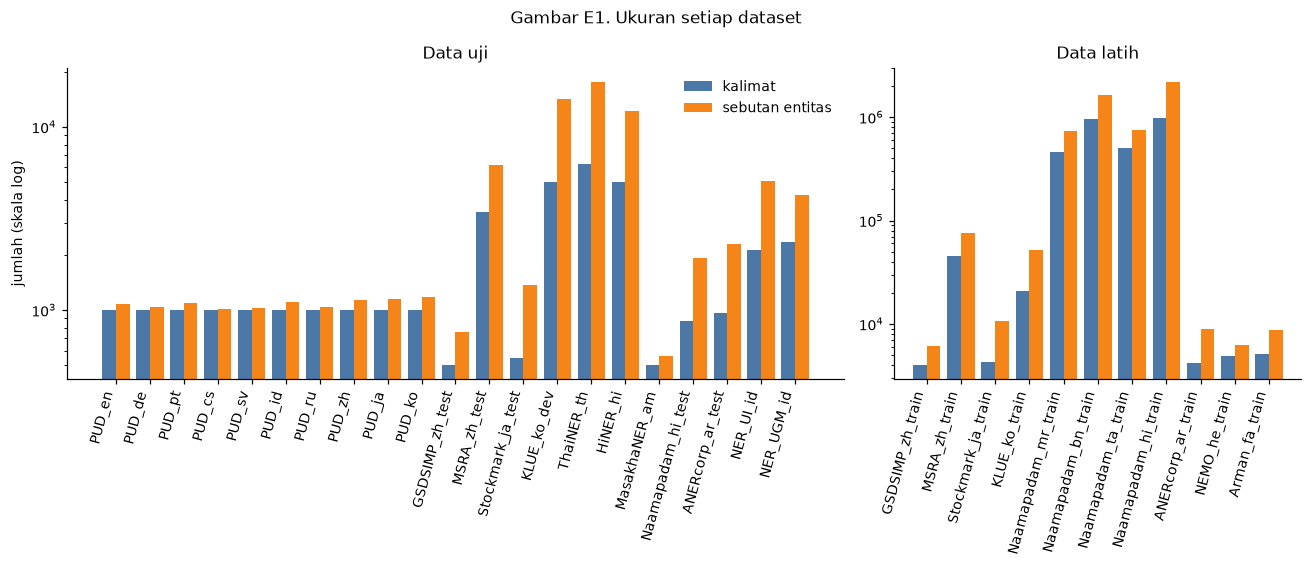

In [5]:
uji, latih = TAB[TAB.peran == "uji"], TAB[TAB.peran == "latih"]
fig, ax = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw=dict(width_ratios=[len(uji), len(latih)]))
for a, T, judul in ((ax[0], uji, "Data uji"), (ax[1], latih, "Data latih")):
    x = range(len(T))
    a.bar([i - 0.2 for i in x], T.kalimat, 0.4, label="kalimat", color="#4C78A8")
    a.bar([i + 0.2 for i in x], T.entitas, 0.4, label="sebutan entitas", color="#F58518")
    a.set_yscale("log"); a.set_xticks(list(x)); a.set_xticklabels(T.index, rotation=75, ha="right"); a.set_title(judul)
ax[0].set_ylabel("jumlah (skala log)"); ax[0].legend(frameon=False)
fig.suptitle("Gambar E1. Ukuran setiap dataset"); fig.tight_layout(); fig.savefig(GAMBAR / "E1_ukuran.png", dpi=160); plt.show()

Data uji berukuran ratusan sampai beberapa ribu kalimat. Data latih bervariasi jauh lebih besar (Naamapadam ratusan ribu
kalimat); karena itu, pada uji perpindahan kedua setiap sumber dipotong menjadi 3.997 kalimat supaya jumlah data tidak
menjadi penyebab perbedaan hasil.

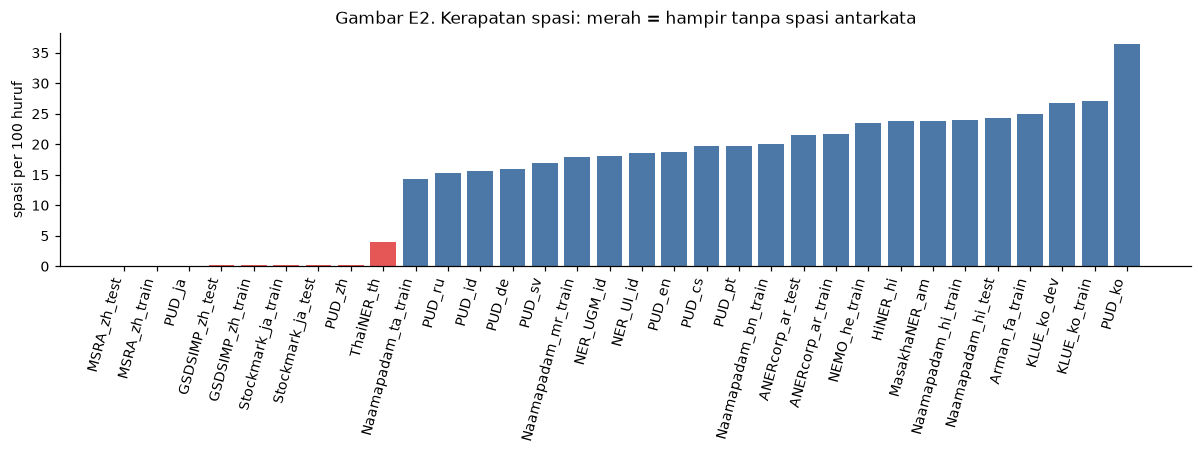

,bahasa,spasi/100 huruf
dataset,,
MSRA_zh_test,zh,0.0
MSRA_zh_train,zh,0.0
PUD_ja,ja,0.0
GSDSIMP_zh_test,zh,0.2
GSDSIMP_zh_train,zh,0.2
Stockmark_ja_train,ja,0.2
Stockmark_ja_test,ja,0.2
PUD_zh,zh,0.3
ThaiNER_th,th,4.0


In [6]:
T = TAB.sort_values("spasi/100 huruf")
warna = ["#E45756" if v < 5 else "#4C78A8" for v in T["spasi/100 huruf"]]
fig, a = plt.subplots(figsize=(11, 4.2))
a.bar(T.index, T["spasi/100 huruf"], color=warna)
a.set_ylabel("spasi per 100 huruf"); a.set_xticks(range(len(T))); a.set_xticklabels(T.index, rotation=75, ha="right")
a.set_title("Gambar E2. Kerapatan spasi: merah = hampir tanpa spasi antarkata")
fig.tight_layout(); fig.savefig(GAMBAR / "E2_spasi.png", dpi=160); plt.show()
T[["bahasa", "spasi/100 huruf"]].head(12)

Mandarin, Jepang, dan Thai hampir tidak memakai spasi, sedangkan Korea berspasi tetapi partikelnya menempel pada kata.
Kelompok inilah yang recall-nya turun pada model rilis, dan intervensi spasi di laporan (menambah spasi ke Mandarin/Jepang,
menghapus spasi dari Inggris/Rusia/Indonesia) menguji langsung peran ciri ini.

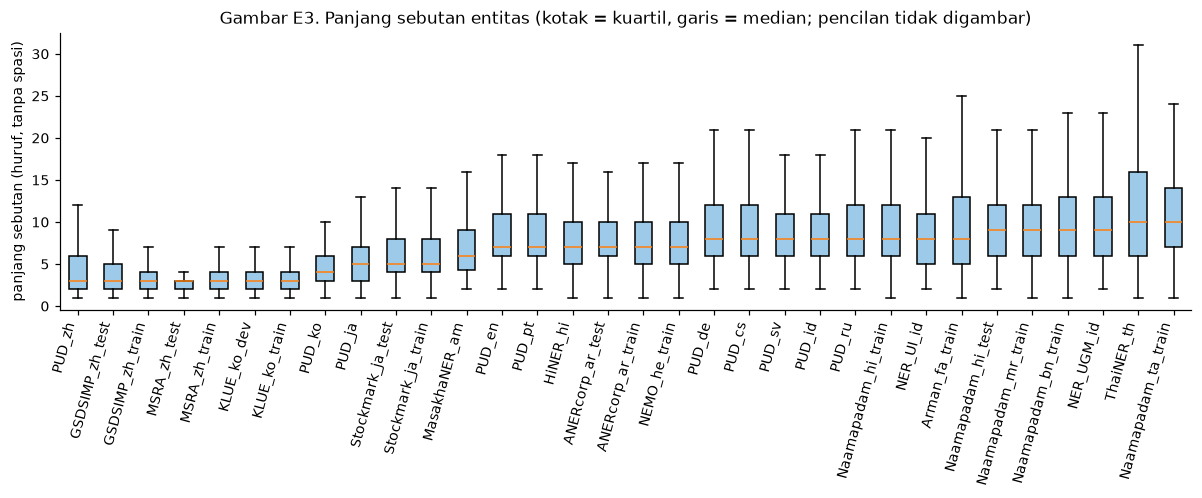

In [7]:
pjg = {k: [sum(not c.isspace() for c in t[a:b]) for t, e in d["rows"] for a, b, _ in e] for k, d in DS.items()}
urut = sorted(pjg, key=lambda k: statistics.median(pjg[k]) if pjg[k] else 0)
fig, a = plt.subplots(figsize=(11, 4.6))
a.boxplot([pjg[k] for k in urut], showfliers=False, patch_artist=True, boxprops=dict(facecolor="#9ECAE9"))
a.set_xticks(range(1, len(urut) + 1)); a.set_xticklabels(urut, rotation=75, ha="right")
a.set_ylabel("panjang sebutan (huruf, tanpa spasi)")
a.set_title("Gambar E3. Panjang sebutan entitas (kotak = kuartil, garis = median; pencilan tidak digambar)")
fig.tight_layout(); fig.savefig(GAMBAR / "E3_panjang.png", dpi=160); plt.show()

Sebutan Mandarin dan Jepang pendek dalam huruf (satu huruf Han setara satu suku kata), sedangkan bahasa berhuruf Latin
lebih panjang. Batas yang salah satu huruf saja pada sebutan 2–3 huruf (misalnya nama tempat Mandarin) langsung membuat
tebakan dianggap salah, sehingga bahasa dengan sebutan pendek lebih peka terhadap kesalahan batas.

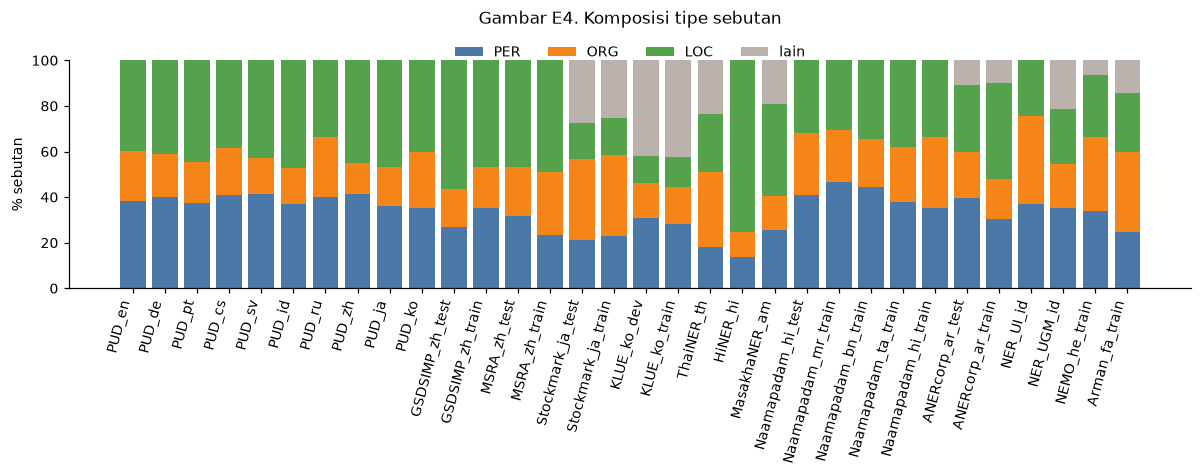

In [8]:
T = TAB[["PER %", "ORG %", "LOC %", "lain %"]]
fig, a = plt.subplots(figsize=(11, 4.4))
bawah = pd.Series(0.0, index=T.index)
for kol, w in zip(T.columns, ["#4C78A8", "#F58518", "#54A24B", "#BAB0AC"]):
    a.bar(T.index, T[kol], bottom=bawah, color=w, label=kol.replace(" %", "")); bawah += T[kol]
a.set_ylabel("% sebutan"); a.set_xticks(range(len(T))); a.set_xticklabels(T.index, rotation=75, ha="right")
a.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.12))
a.set_title("Gambar E4. Komposisi tipe sebutan", pad=24)
fig.tight_layout(); fig.savefig(GAMBAR / "E4_tipe.png", dpi=160); plt.show()

Laporan menilai hanya PER, ORG, dan LOC. Bagian abu-abu adalah sebutan sah yang tidak ikut dinilai, misalnya tanggal dan
angka di KLUE, URL dan tanggal di ThaiNER, MISC di ANERcorp. Ini salah satu alasan presisi terhadap kunci jawaban adalah
batas bawah: tebakan ToMMeR yang benar untuk tipe "lain" tetap dihitung salah.

## 4. Pemeriksaan khusus

### 4a. PUD: kalimat sama, sebutan berbeda jumlah

PUD berisi 1.000 kalimat yang sama yang diterjemahkan ke 10 bahasa. Jumlah sebutannya tetap berbeda per bahasa karena
penerjemahan dan pedoman anotasi; ini perlu diingat saat membandingkan recall antarbahasa.

In [9]:
pud = TAB.loc[[f"PUD_{k}" for k in PUD], ["bahasa", "kalimat", "entitas", "ent/kal", "huruf/kal", "spasi/100 huruf", "pjg_ent huruf", "akhir_kal %"]]
pud

,bahasa,kalimat,entitas,ent/kal,huruf/kal,spasi/100 huruf,pjg_ent huruf,akhir_kal %
dataset,,,,,,,,
PUD_en,en,1000,1075,1.1,92.7,18.8,7.0,15.1
PUD_de,de,1000,1039,1.0,109.5,15.9,8.0,8.1
PUD_pt,pt,1000,1099,1.1,100.0,19.8,7.0,16.5
PUD_cs,cs,1000,1008,1.0,89.4,19.7,8.0,18.3
PUD_sv,sv,1000,1029,1.0,95.3,17.0,8.0,16.6
PUD_id,id,1000,1110,1.1,103.2,15.6,8.0,17.7
PUD_ru,ru,1000,1036,1.0,101.1,15.3,8.0,16.9
PUD_zh,zh,1000,1139,1.1,35.5,0.3,3.0,4.1
PUD_ja,ja,1000,1150,1.1,48.3,0.0,5.0,0.0


### 4b. Korea: partikel yang menempel pada sebutan

Di bahasa Korea, partikel (misalnya 은, 는, 이, 가, 의, 에) menempel pada kata. Kalau anotasi PUD ko memasukkan partikel ke
dalam sebutan sedangkan data latih KLUE tidak, model belajar batas yang berbeda dari kunci jawaban. Itulah sebabnya PUD
Korea dinilai **per kata** di laporan.

In [10]:
PARTIKEL = set("은는이가의에를을와과도로서")
def partikel(rows):
    e = [t[a:b] for t, ents in rows for a, b, ty in ents if plo(ty) != "lain"]
    return 100 * sum(x[-1:] in PARTIKEL for x in e) / max(1, len(e)), len(e)
kor = pd.DataFrame([dict(dataset=k, sebutan_PLO=partikel(DS[k]["rows"])[1], berakhir_partikel_pct=partikel(DS[k]["rows"])[0])
                    for k in ("PUD_ko", "KLUE_ko_dev", "KLUE_ko_train")]).set_index("dataset")
kor

,sebutan_PLO,berakhir_partikel_pct
dataset,,
PUD_ko,1172,56.7
KLUE_ko_dev,8249,4.5
KLUE_ko_train,29607,4.7


### 4c. Awalan yang menempel pada nama (Arab, Ibrani, Amharik)

Bahasa Semit menempelkan awalan seperti "dan", "di", "ke" pada kata, misalnya والقاهرة = و ("dan") + القاهرة ("Kairo").
Ukuran **kasar** = sebutan yang diawali huruf awalan (termasuk nama yang memang diawali huruf itu). Ukuran **menempel** =
sebutan berbentuk awalan + sebutan lain yang ada di korpus yang sama, jadi lebih tegas. Ini pemeriksaan K4 di laporan.

In [11]:
AWALAN = {"ANERcorp_ar_test": ["ال", "و", "ب", "ل"], "ANERcorp_ar_train": ["ال", "و", "ب", "ل"],
          "NEMO_he_train": ["ה", "ו", "ב", "ל", "מ", "ש"], "Arman_fa_train": ["ال", "و", "ب", "ل"],
          "MasakhaNER_am": ["የ", "በ", "ለ", "ከ"]}
baris = []
for k, aw in AWALAN.items():
    e = [t[a:b] for t, ents in DS[k]["rows"] for a, b, ty in ents if plo(ty) != "lain"]
    semua = set(e)
    for p in aw:
        baris.append(dict(dataset=k, awalan=p, kasar_pct=100 * sum(x.startswith(p) for x in e) / max(1, len(e)),
                          menempel_pct=100 * sum(x.startswith(p) and x[len(p):] in semua for x in e) / max(1, len(e))))
pd.DataFrame(baris).pivot(index="dataset", columns="awalan", values="menempel_pct").round(1)

awalan,ב,ה,ו,ל,מ,ש,ال,ب,ل,و,ለ,በ,ከ,የ
dataset,,,,,,,,,,,,,,
ANERcorp_ar_test,NaN,NaN,NaN,NaN,NaN,NaN,0.6,2.0,1.0,2.8,NaN,NaN,NaN,NaN
ANERcorp_ar_train,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.3,1.4,4.4,NaN,NaN,NaN,NaN
Arman_fa_train,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
MasakhaNER_am,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.1,6.9,1.5,11.1
NEMO_he_train,8.8,1.0,2.4,3.6,2.0,1.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Angka di atas adalah ukuran **menempel**. ANERcorp (Arab) dan NEMO (Ibrani) sama-sama memasukkan awalan ke dalam sebutan,
jadi aturan labelnya sejalan; Persia hampir nol karena awalan tersebut tidak menempel dalam bahasa Persia. Pada Amharik,
awalan የ/በ ikut di dalam sebutan; ini menjelaskan mengapa kecocokan token persis Amharik hampir nol pada model rilis,
sedangkan kecocokan per huruf lebih tinggi.

### 4d. Kebocoran: kalimat latih yang juga ada di data uji

Kalimat yang sama (spasi diabaikan) di data latih dan data uji membuat model "melihat soal ujian". Angka di bawah adalah
kebocoran pada data **mentah**; di eksperimen kalimat-kalimat ini dibuang dari data latih sebelum melatih (misalnya 176
kalimat ANERcorp), sehingga kebocoran pada data yang benar-benar dipakai adalah 0.

In [12]:
PASANGAN = [("GSDSIMP_zh_train", ["GSDSIMP_zh_test", "PUD_zh", "MSRA_zh_test"]), ("MSRA_zh_train", ["MSRA_zh_test", "PUD_zh"]),
            ("Stockmark_ja_train", ["Stockmark_ja_test", "PUD_ja"]), ("KLUE_ko_train", ["KLUE_ko_dev", "PUD_ko"]),
            ("Naamapadam_hi_train", ["Naamapadam_hi_test", "HiNER_hi"]), ("ANERcorp_ar_train", ["ANERcorp_ar_test"])]
baris = []
for latih, ujis in PASANGAN:
    L = {norm(t) for t, _ in DS[latih]["rows"]}
    for u in ujis:
        U = {norm(t) for t, _ in DS[u]["rows"]}
        baris.append(dict(latih=latih, uji=u, kalimat_uji=len(U), sama=len(L & U), sama_pct=f"{100 * len(L & U) / max(1, len(U)):.2f}"))
pd.DataFrame(baris)

,latih,uji,kalimat_uji,sama,sama_pct
0,GSDSIMP_zh_train,GSDSIMP_zh_test,500,0,0.00
1,GSDSIMP_zh_train,PUD_zh,1000,0,0.00
2,GSDSIMP_zh_train,MSRA_zh_test,3437,0,0.00
3,MSRA_zh_train,MSRA_zh_test,3437,0,0.00
4,MSRA_zh_train,PUD_zh,1000,0,0.00
5,Stockmark_ja_train,Stockmark_ja_test,550,0,0.00
6,Stockmark_ja_train,PUD_ja,1000,0,0.00
7,KLUE_ko_train,KLUE_ko_dev,5000,1,0.02
8,KLUE_ko_train,PUD_ko,1000,0,0.00
9,Naamapadam_hi_train,Naamapadam_hi_test,864,17,1.97


## 5. Pile-NER: data latih asli ToMMeR

Pile-NER berisi teks bahasa Inggris dari The Pile dengan sebutan yang dilabeli GPT-3.5 dalam bentuk percakapan:
"Text: …", lalu untuk setiap tipe pertanyaan "What describes <tipe> in the text?" dengan jawaban daftar sebutan. ToMMeR
hanya memakai batas sebutannya; tipenya diabaikan.

In [13]:
pile = json.loads(unduh(f"{HF}datasets/Universal-NER/Pile-NER-type/resolve/main/train.json", "pile_ner_train.json").read_text(encoding="utf8"))
teks, sebutan, tipe, kosong = [], [], Counter(), 0
for x in pile:
    c = x["conversations"]
    t = c[0]["value"][len("Text: "):] if c[0]["value"].startswith("Text: ") else c[0]["value"]
    teks.append(t); n0 = len(sebutan)
    for q, j in zip(c[2::2], c[3::2]):
        m = re.match(r"What describes (.+) in the text\?", q["value"])
        try:
            daftar_s = json.loads(j["value"])
        except Exception:
            daftar_s = []
        if m: tipe[m.group(1).lower()] += len(daftar_s)
        sebutan += daftar_s
    kosong += len(sebutan) == n0
P = pd.Series({"teks": len(teks), "teks latih (tanpa 1.000 dev)": len(teks) - 1000, "sebutan": len(sebutan),
               "nama tipe unik": len(tipe), "sebutan/teks": len(sebutan) / len(teks), "teks tanpa sebutan %": 100 * kosong / len(teks),
               "kata/teks (median)": statistics.median(len(t.split()) for t in teks),
               "kata/sebutan (rata-rata)": statistics.mean(len(s.split()) for s in sebutan if isinstance(s, str))})
display(P.to_frame("Pile-NER").round(2))
pd.DataFrame(tipe.most_common(15), columns=["tipe", "sebutan"])

,Pile-NER
teks,45889.0
teks latih (tanpa 1.000 dev),44889.0
sebutan,621796.0
nama tipe unik,12963.0
sebutan/teks,13.6
teks tanpa sebutan %,0.8
kata/teks (median),186.0
kata/sebutan (rata-rata),1.8


,tipe,sebutan
0,person,59527
1,organization,48184
2,concept,42698
3,location,41308
4,product,26337
5,date,15533
6,medical condition,13041
7,technology,11092
8,object,10691
9,event,8302


Pile-NER sangat beragam (belasan ribu nama tipe) dan seluruhnya bahasa Inggris. Inilah yang membuat ToMMeR kuat pada
bahasa berhuruf Latin, dan alasan uji perpindahan selalu mencampur Pile-NER dengan data bahasa sumber (porsi 20%
sebutan) alih-alih mengganti Pile-NER.

## 6. Ringkasan temuan

| # | Temuan | Angka (dari keluaran di atas) | Kaitan dengan laporan |
|---|---|---|---|
| 1 | PUD benar-benar paralel | 10 bahasa × 1.000 kalimat yang sama; 1.008–1.172 sebutan PLO | perbedaan recall antarbahasa PUD tidak berasal dari isi kalimat |
| 2 | Mandarin dan Jepang hampir tanpa spasi | spasi per 100 huruf: PUD zh 0,3; PUD ja 0,0; MSRA 0,0; Stockmark 0,2 (bahasa Latin/Kiril 15–20) | sejalan dengan turunnya recall model rilis di zh/ja; dasar intervensi spasi |
| 3 | Sebutan zh/ja/ko pendek | median panjang sebutan: zh 3 huruf, ko 4 (PUD) / 3 (KLUE), ja 5; bahasa Latin 7–8 | salah satu huruf di tepi langsung membuat tebakan salah |
| 4 | Aturan label Korea berbeda antara PUD dan KLUE | sebutan berakhir partikel: PUD_ko 56,7%, KLUE 4,5–4,7% | PUD Korea dinilai per kata; model yang dilatih KLUE belajar batas tanpa partikel |
| 5 | Awalan menempel di dalam sebutan | NEMO (Ibrani) ב 8,8%; ANERcorp (Arab) و 4,4% (latih); MasakhaNER (Amharik) የ 11,1%, በ 6,9% | menjelaskan rendahnya kecocokan token persis pada Amharik |
| 6 | Banyak tipe di luar PLO | lain %: KLUE 42%, Stockmark 25–28%, ThaiNER 23%, NER UGM 22%, MasakhaNER 19% | presisi terhadap kunci PLO adalah batas bawah |
| 7 | Kebocoran latih–uji hampir nol untuk zh/ja/ko/ar | GSDSIMP, MSRA, Stockmark: 0 kalimat; KLUE 1 dari 5.000; ANERcorp 1 dari 926 | hasil uji zh/ja/ko/ar tidak dipengaruhi kebocoran |
| 8 | **Kebocoran kecil pada Hindi** | 143 dari 4.998 kalimat HiNER (2,9%) dan 17 dari 864 kalimat uji Naamapadam (2,0%) juga ada di data latih Naamapadam-hi | hasil model `hi` pada HiNER/Naamapadam perlu diberi catatan; pengaruhnya paling banyak sekitar 2–3% kalimat |
| 9 | Pile-NER hanya bahasa Inggris, tetapi tipenya sangat beragam | 45.889 teks, 621.796 sebutan (jawaban per pertanyaan tipe), 12.963 nama tipe (huruf kecil) | alasan Pile-NER tetap dicampur, bukan diganti, pada uji perpindahan |

Catatan untuk temuan 9: Tabel 3 laporan CP1 mencatat 887.917 entitas dan 12.301 nama tipe. Jumlah teksnya sama
(45.889), tetapi cara hitung sebutan dan tipe di CP1 tidak tercatat, sehingga kedua angka itu belum bisa disamakan.

In [14]:
print("Tabel ringkas tersimpan:", GAMBAR / "eda_ringkas.csv")
print("Grafik:", sorted(p.name for p in GAMBAR.glob("*.png")))

Tabel ringkas tersimpan: gambar_eda\eda_ringkas.csv
Grafik: ['E1_ukuran.png', 'E2_spasi.png', 'E3_panjang.png', 'E4_tipe.png']
